# Preliminary Exploratory Data Analysis

Auto-generated overview of a CSV dataset. Drop your file in `data/raw/` and run all cells.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline
print("Libraries loaded correctly")

Libraries loaded correctly


## 1. Data Loading

Detects and loads the CSVs found in `data/raw/`.

In [2]:
raw_dir = Path.cwd().parent.parent / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

csv_files = list(raw_dir.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {raw_dir}. Place a CSV file there and rerun.")

file_path = csv_files[0]
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Loading: devices-1681209661.csv
Shape: 118,249 rows x 15 columns


In [3]:
df.head(10)

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
0,1,NaN,NaN,IVD Other,NaN,NaN,Cell-Dyn Emerald Cleanser,NaN,NaN,NaN,tur-cell-dyn-emerald-cleanser,TUR,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,Class IIB,NaN,NaN,"TECNIS Monofocal 1-piece, TECNIS 1-Piece IOL w...",NaN,NaN,NaN,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,TUR,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
2,3,NaN,NaN,Class IIA,NaN,NaN,Centurion FMS Package for Centurion Vision System,NaN,NaN,NaN,tur-centurion-fms-package-for-centurion-vision...,TUR,3,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
3,4,NaN,NaN,Class IIB,NaN,NaN,Focusforce intraocular foldable lenses,NaN,NaN,NaN,tur-focusforce-intraocular-foldable-lenses,TUR,4,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
4,5,NaN,NaN,IVD Other,NaN,NaN,Cholesterol HDL Direct,NaN,NaN,NaN,tur-cholesterol-hdl-direct,TUR,5,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
5,6,NaN,NaN,IVD Other,NaN,NaN,Blood Glucose Test Strip,NaN,NaN,NaN,tur-blood-glucose-test-strip,TUR,6,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
6,7,NaN,NaN,Class IIA,NaN,NaN,Super Arrow-Flex(R) Percutaneous Sheath Introd...,NaN,NaN,NaN,tur-super-arrow-flex-r-percutaneous-sheath-int...,TUR,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
7,8,NaN,NaN,Class III,NaN,NaN,Catheter introducer,NaN,NaN,NaN,tur-catheter-introducer,TUR,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
8,9,NaN,NaN,Class IIA,NaN,NaN,22g Bi-Manual Aspiration Pull Handle 0.38mm Port,NaN,NaN,NaN,tur-22g-bi-manual-aspiration-pull-handle-0-38m...,TUR,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
9,10,NaN,NaN,Class III,NaN,NaN,Spinocath,NaN,NaN,NaN,tur-spinocath,TUR,9,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


## 2. Column Overview

Data types, non-null counts, and memory usage.

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 118249 entries, 0 to 118248
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   id                    118249 non-null  int64
 1   classification        35601 non-null   str  
 2   code                  36218 non-null   str  
 3   description           89606 non-null   str  
 4   distributed_to        33626 non-null   str  
 5   implanted             34898 non-null   str  
 6   name                  118218 non-null  str  
 7   number                63800 non-null   str  
 8   quantity_in_commerce  31929 non-null   str  
 9   risk_class            32948 non-null   str  
 10  slug                  118249 non-null  str  
 11  country               118248 non-null  str  
 12  manufacturer_id       118249 non-null  int64
 13  created_at            118249 non-null  str  
 14  updated_at            118249 non-null  str  
dtypes: int64(2), str(13)
memory usage: 13.5 MB
No

In [5]:
dtype_counts = df.dtypes.value_counts()
print("Column type distribution:")
for dtype, count in dtype_counts.items():
    print(f"  {dtype.name}: {count} columns")

Column type distribution:
  str: 13 columns
  int64: 2 columns


## 3. Missing Values Analysis

In [29]:
print(f"{df.isna().sum().sum()}")

587398


In [30]:
# Per-column nulls
missing_cols = pd.DataFrame({
    "Missing": df.isna().sum(),
    "%": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing", ascending=False)

missing_cols = missing_cols[missing_cols["Missing"] > 0]
if missing_cols.empty:
    print("No missing values found.")
else:
    display(missing_cols)
    print(f"\nTotal missing values: {df.isna().sum().sum()}")

,Missing,%
quantity_in_commerce,86320,73.00
risk_class,85301,72.14
distributed_to,84623,71.56
implanted,83351,70.49
classification,82648,69.89
code,82031,69.37
number,54449,46.05
description,28643,24.22
name,31,0.03
country,1,0.00



Total missing values: 587398


In [8]:
# Per-row null distribution
nulls_per_row = df.isna().sum(axis=1)

print("Rows with nulls:")
for threshold in [1, 2, 5, 10, 20, 50]:
    count = (nulls_per_row >= threshold).sum()
    print(f"  ≥{threshold:>3} nulls: {count:>6,} rows ({count / len(df) * 100:>5.1f}%)")

print(f"\nNulls per row — distribution:")
dist = nulls_per_row.value_counts().sort_index()
display(dist.head(20).to_frame("# rows"))

Rows with nulls:
  ≥  1 nulls: 87,693 rows ( 74.2%)
  ≥  2 nulls: 85,323 rows ( 72.2%)
  ≥  5 nulls: 84,633 rows ( 71.6%)
  ≥ 10 nulls:      1 rows (  0.0%)
  ≥ 20 nulls:      0 rows (  0.0%)
  ≥ 50 nulls:      0 rows (  0.0%)

Nulls per row — distribution:


,# rows
0,30556
1,2370
2,98
3,186
4,406
5,732
6,28535
7,35155
8,20205
9,5


In [10]:
# Column drop recommendations (>40% nulls)
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "Null %": null_pct.round(2),
    "Recommendation": null_pct.apply(
        lambda p: "DROP (>40%)" if p > 40 else "KEEP"
    )
}).sort_values("Null %", ascending=False)

to_drop = rec_df[rec_df["Recommendation"] == "DROP (>40%)"]
if not to_drop.empty:
    print("=" * 55)
    print(f"  {len(to_drop)} column(s) with >40% nulls — recommended for removal")
    print("=" * 55)
    display(to_drop)
else:
    print("No columns exceed 40% nulls — none recommended for removal.")

  7 column(s) with >40% nulls — recommended for removal


,Null %,Recommendation
quantity_in_commerce,73.00,DROP (>40%)
risk_class,72.14,DROP (>40%)
distributed_to,71.56,DROP (>40%)
implanted,70.49,DROP (>40%)
classification,69.89,DROP (>40%)
code,69.37,DROP (>40%)
number,46.05,DROP (>40%)


## 4. Numerical Columns – Descriptive Statistics

In [11]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (2): ['id', 'manufacturer_id']
Categorical / text columns (13): ['classification', 'code', 'description', 'distributed_to', 'implanted', 'name', 'number', 'quantity_in_commerce', 'risk_class', 'slug', 'country', 'created_at', 'updated_at']


In [12]:
if num_cols:
    display(df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
id,118249.0,59125.000000,34135.690328,1.0,1183.48,5913.4,29563.0,59125.0,88687.0,112336.6,117066.52,118249.0
manufacturer_id,118249.0,15022.948321,9117.177777,1.0,614.48,2110.0,6097.0,14880.0,24087.0,30245.6,31095.52,31827.0


## 5. Categorical Columns – Value Counts

In [13]:
for col in cat_cols[:10]:
    vc = df[col].value_counts(dropna=False).head(15)
    print(f"\n--- {col} ({vc.sum():,} non-null / {df[col].nunique():,} unique) ---")
    print(vc.to_string())


--- classification (117,757 non-null / 16 unique) ---
classification
NaN                                                   82648
Cardiovascular Devices                                 5481
Orthopedic Devices                                     5353
General Hospital and Personal Use Devices              4245
General and Plastic Surgery Devices                    4160
Radiology Devices                                      3744
Clinical Chemistry and Clinical Toxicology Devices     2589
Anesthesiology Devices                                 2265
Gastroenterology-Urology Devices                       2080
Immunology and Microbiology Devices                    1149
Neurological Devices                                   1080
Hematology and Pathology Devices                       1004
Dental Devices                                          827
Ophthalmic Devices                                      631
Physical Medicine Devices                               501

--- code (88,135 non-null / 3

## 6. Outlier Detection (IQR method)

In [14]:
if num_cols:
    outlier_data = []
    for col in num_cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)][col].dropna()
        if len(outliers) > 0:
            outlier_data.append({
                "Column": col,
                "Outliers": len(outliers),
                "%": round(len(outliers) / df[col].notna().sum() * 100, 2),
                "Lower bound": round(lower, 2),
                "Upper bound": round(upper, 2)
            })
    if outlier_data:
        outlier_df = pd.DataFrame(outlier_data).sort_values("Outliers", ascending=False)
        display(outlier_df)
    else:
        print("No outliers detected via IQR.")

No outliers detected via IQR.


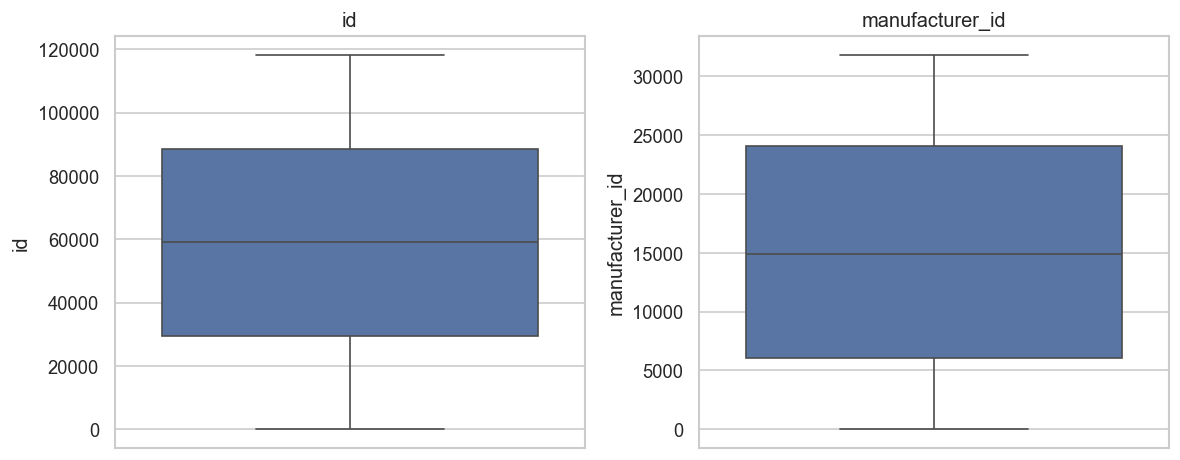

In [15]:
if num_cols:
    n_cols = min(6, len(num_cols))
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 4))
    if n_cols == 1:
        axes = [axes]
    for ax, col in zip(axes, num_cols[:n_cols]):
        sns.boxplot(y=df[col], ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

## 7. Correlation Analysis

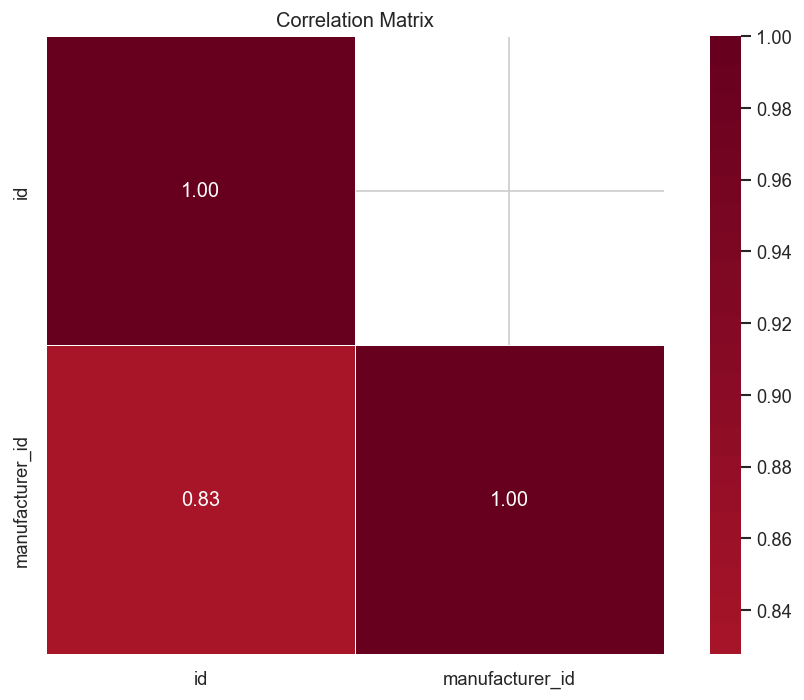

Top 10 strongest correlations:
  id  –  manufacturer_id: +0.8278


In [16]:
if len(num_cols) >= 2:
    corr = df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 20,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[
        corr_unstacked.index.get_level_values(0) !=
        corr_unstacked.index.get_level_values(1)
    ]
    top_corr = corr_unstacked.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (col1, col2), val in top_corr.items():
        print(f"  {col1}  –  {col2}: {corr.loc[col1, col2]:+.4f}")

## 8. Distribution of Numerical Columns

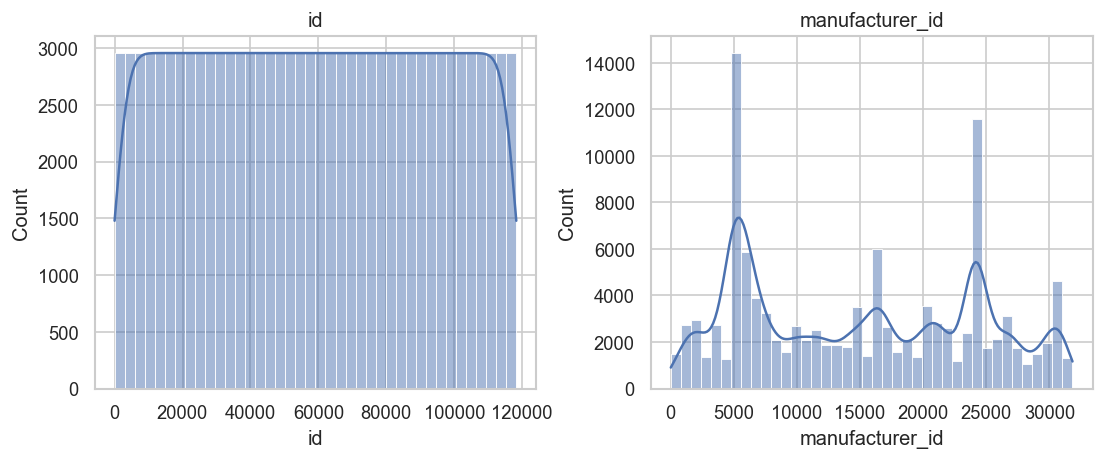

In [17]:
if num_cols:
    n_hist = min(9, len(num_cols))
    n_rows = (n_hist + 2) // 3
    fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
    axes = axes.flatten()
    for ax, col in zip(axes, num_cols[:n_hist]):
        sns.histplot(df[col].dropna(), kde=True, bins=40, ax=ax)
        ax.set_title(col)
    for ax in axes[n_hist:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

## 9. Summary

In [18]:
rows_with_nulls = (df.isna().sum(axis=1) >= 1).sum()
cols_to_drop = (df.isna().mean() * 100 > 40).sum()

print("=" * 60)
print("PRELIMINARY EDA SUMMARY")
print("=" * 60)

print(f"\nDataset: {file_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Missing cells: {df.isna().sum().sum():,} / {df.size:,} ({df.isna().sum().sum() / df.size * 100:.2f}%)")
print(f"Rows with ≥1 null: {rows_with_nulls:,} ({rows_with_nulls / len(df) * 100:.1f}%)")
print(f"Columns with >40% nulls (recommended for removal): {cols_to_drop}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

PRELIMINARY EDA SUMMARY

Dataset: devices-1681209661.csv
Dimensions: 118,249 rows x 15 columns
Missing cells: 587,398 / 1,773,735 (33.12%)
Rows with ≥1 null: 87,693 (74.2%)
Columns with >40% nulls (recommended for removal): 7
Duplicate rows: 0
Numerical columns: 2
Categorical columns: 13
Memory usage: 127.90 MB
